# 04_Model_Comparison — XGBoost vs LSTM

**Project:** Remaining Useful Life Prediction for Turbofan Engines Using XGBoost and LSTM  
**Dataset:** NASA C-MAPSS FD001

This notebook compares the final XGBoost and LSTM models.

The main aim is to answer this question:

> Does using an LSTM sequence model improve RUL prediction compared with XGBoost on FD001?

### This notebook compares

- RMSE
- MAE
- R²
- NASA score
- training time
- error for each test engine
- error at different RUL ranges
- engines with the largest errors

Run `02_XGBoost_FINAL.ipynb` and `03_LSTM_FINAL.ipynb` first so their output folders are available.


## 1. Imports

Only the saved results from the two completed model notebooks are used here.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

## 2. Output folders

The previous notebooks save their results in:

- `xgboost_outputs`
- `lstm_outputs`

This notebook reads those files instead of training the models again.


In [2]:
XGB_DIR = Path("xgboost_outputs")
LSTM_DIR = Path("lstm_outputs")
OUTPUT_DIR = Path("comparison_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

required_files = [
    XGB_DIR / "xgboost_metrics.json",
    XGB_DIR / "xgboost_test_predictions.csv",
    XGB_DIR / "xgboost_error_by_rul_band.csv",
    LSTM_DIR / "lstm_seed_results.csv",
    LSTM_DIR / "lstm_test_predictions.csv",
    LSTM_DIR / "lstm_error_by_rul_band.csv",
]

missing = [str(p) for p in required_files if not p.exists()]

if missing:
    print("Missing files:")
    for p in missing:
        print("-", p)
    raise FileNotFoundError(
        "Run 02_XGBoost_FINAL.ipynb and 03_LSTM_FINAL.ipynb first."
    )

print("All required files were found.")

All required files were found.


## 3. Load the saved results


In [3]:
with open(XGB_DIR / "xgboost_metrics.json", "r") as f:
    xgb_metrics = json.load(f)

xgb_pred = pd.read_csv(
    XGB_DIR / "xgboost_test_predictions.csv"
)

xgb_bands = pd.read_csv(
    XGB_DIR / "xgboost_error_by_rul_band.csv"
)

lstm_seed_results = pd.read_csv(
    LSTM_DIR / "lstm_seed_results.csv"
)

lstm_pred = pd.read_csv(
    LSTM_DIR / "lstm_test_predictions.csv"
)

lstm_bands = pd.read_csv(
    LSTM_DIR / "lstm_error_by_rul_band.csv"
)

print("XGBoost predictions:", xgb_pred.shape)
print("LSTM predictions:", lstm_pred.shape)
print("LSTM runs:", len(lstm_seed_results)
     )

XGBoost predictions: (100, 7)
LSTM predictions: (100, 8)
LSTM runs: 3


## 4. Check that both models use the same test engines

The models should be compared using the same 100 FD001 test engines and the same true RUL values.


In [4]:
xgb_units = xgb_pred["unit"].astype(int).to_numpy()
lstm_units = lstm_pred["unit"].astype(int).to_numpy()

assert np.array_equal(xgb_units, lstm_units), (
    "The test engine IDs are not in the same order."
)

assert np.allclose(
    xgb_pred["actual_RUL"].to_numpy(),
    lstm_pred["actual_RUL"].to_numpy()
), "The true RUL values are different."

print("Test engines:", len(xgb_units))
print("Engine IDs match:", True)
print("Actual RUL values match:", True)

Test engines: 100
Engine IDs match: True
Actual RUL values match: True


## 5. Calculate the final model results

The LSTM was trained three times using different random seeds.

The mean and standard deviation across the three runs are used for the main LSTM result.

The averaged prediction from the three LSTM models is also shown as an extra result.


In [5]:
def regression_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    error = predicted - actual
    rmse = np.sqrt(np.mean(error ** 2))
    mae = np.mean(np.abs(error))

    ss_res = np.sum((actual - predicted) ** 2)
    ss_tot = np.sum((actual - np.mean(actual)) ** 2)
    r2 = 1 - ss_res / ss_tot

    nasa = np.sum(
        np.where(
            error < 0,
            np.exp(-error / 13.0) - 1.0,
            np.exp(error / 10.0) - 1.0
        )
    )

    return {
        "RMSE": float(rmse),
        "MAE": float(mae),
        "R2": float(r2),
        "NASA_score": float(nasa)
    }


lstm_mean_rmse = lstm_seed_results["test_RMSE"].mean()
lstm_std_rmse = lstm_seed_results["test_RMSE"].std()

lstm_mean_mae = lstm_seed_results["test_MAE"].mean()
lstm_std_mae = lstm_seed_results["test_MAE"].std()

lstm_mean_r2 = lstm_seed_results["test_R2"].mean()
lstm_std_r2 = lstm_seed_results["test_R2"].std()

lstm_mean_nasa = lstm_seed_results["test_NASA_score"].mean()
lstm_std_nasa = lstm_seed_results["test_NASA_score"].std()

lstm_ensemble = regression_metrics(
    lstm_pred["actual_RUL"],
    lstm_pred["predicted_RUL_mean"]
)

main_comparison = pd.DataFrame({
    "Model": ["XGBoost", "LSTM mean (3 seeds)"],
    "RMSE": [
        xgb_metrics["test_rmse"],
        lstm_mean_rmse
    ],
    "MAE": [
        xgb_metrics["test_mae"],
        lstm_mean_mae
    ],
    "R2": [
        xgb_metrics["test_r2"],
        lstm_mean_r2
    ],
    "NASA_score": [
        xgb_metrics["test_nasa_score"],
        lstm_mean_nasa
    ]
})

display(main_comparison.round(4))

print("\nLSTM variation across seeds")
print(f"RMSE: {lstm_mean_rmse:.4f} ± {lstm_std_rmse:.4f}")
print(f"MAE:  {lstm_mean_mae:.4f} ± {lstm_std_mae:.4f}")
print(f"R²:   {lstm_mean_r2:.4f} ± {lstm_std_r2:.4f}")
print(f"NASA: {lstm_mean_nasa:.4f} ± {lstm_std_nasa:.4f}")

print("\nAveraged LSTM prediction")
for name, value in lstm_ensemble.items():
    print(f"{name}: {value:.4f}")

,Model,RMSE,MAE,R2,NASA_score
0,XGBoost,18.4838,13.4419,0.8022,630.9485
1,LSTM mean (3 seeds),16.0610,11.5121,0.8501,403.3767



LSTM variation across seeds
RMSE: 16.0610 ± 1.1059
MAE:  11.5121 ± 0.7419
R²:   0.8501 ± 0.0205
NASA: 403.3767 ± 49.6573

Averaged LSTM prediction
RMSE: 14.9067
MAE: 10.8442
R2: 0.8713
NASA_score: 308.7695


## 6. Percentage improvement

A positive value means the LSTM result is better than XGBoost.


In [6]:
rmse_improvement = (
    (xgb_metrics["test_rmse"] - lstm_mean_rmse)
    / xgb_metrics["test_rmse"]
    * 100
)

mae_improvement = (
    (xgb_metrics["test_mae"] - lstm_mean_mae)
    / xgb_metrics["test_mae"]
    * 100
)

print(
    f"LSTM RMSE improvement over XGBoost: "
    f"{rmse_improvement:.2f}%"
)

print(
    f"LSTM MAE improvement over XGBoost: "
    f"{mae_improvement:.2f}%"
)

LSTM RMSE improvement over XGBoost: 13.11%
LSTM MAE improvement over XGBoost: 14.36%


## 7. Training time

Training time is included to show the difference in model cost.

The exact time depends on the computer, so it should not be treated as a universal benchmark.


In [7]:
xgb_training_time = float(xgb_metrics["training_seconds"])

lstm_mean_training_time = (
    lstm_seed_results["training_seconds"].mean()
)

lstm_total_training_time = (
    lstm_seed_results["training_seconds"].sum()
)

training_time_table = pd.DataFrame({
    "Model": [
        "XGBoost",
        "LSTM average per seed",
        "LSTM total for 3 seeds"
    ],
    "Training_seconds": [
        xgb_training_time,
        lstm_mean_training_time,
        lstm_total_training_time
    ]
})

display(training_time_table.round(3))

,Model,Training_seconds
0,XGBoost,0.784
1,LSTM average per seed,40.337
2,LSTM total for 3 seeds,121.010


## 8. Compare the error for every test engine

The averaged LSTM prediction is used here because it gives one final prediction for each engine.


In [8]:
engine_comparison = pd.DataFrame({
    "unit": xgb_pred["unit"].astype(int),
    "actual_RUL": xgb_pred["actual_RUL"].astype(float),
    "xgboost_prediction": xgb_pred["predicted_RUL"].astype(float),
    "lstm_prediction": lstm_pred["predicted_RUL_mean"].astype(float)
})

engine_comparison["xgboost_error"] = (
    engine_comparison["xgboost_prediction"]
    - engine_comparison["actual_RUL"]
)

engine_comparison["lstm_error"] = (
    engine_comparison["lstm_prediction"]
    - engine_comparison["actual_RUL"]
)

engine_comparison["xgboost_absolute_error"] = (
    engine_comparison["xgboost_error"].abs()
)

engine_comparison["lstm_absolute_error"] = (
    engine_comparison["lstm_error"].abs()
)

engine_comparison["absolute_error_change"] = (
    engine_comparison["xgboost_absolute_error"]
    - engine_comparison["lstm_absolute_error"]
)

display(engine_comparison.head(15).round(3))

,unit,actual_RUL,xgboost_prediction,lstm_prediction,xgboost_error,lstm_error,xgboost_absolute_error,lstm_absolute_error,absolute_error_change
0,1,112.0,122.899,112.864,10.899,0.864,10.899,0.864,10.035
1,2,98.0,121.145,112.983,23.145,14.983,23.145,14.983,8.162
2,3,69.0,54.786,45.807,-14.214,-23.193,14.214,23.193,-8.979
3,4,82.0,81.621,68.073,-0.379,-13.927,0.379,13.927,-13.548
4,5,91.0,94.917,74.047,3.917,-16.953,3.917,16.953,-13.037
5,6,93.0,92.568,102.048,-0.432,9.048,0.432,9.048,-8.616
6,7,91.0,104.793,112.487,13.793,21.487,13.793,21.487,-7.694
7,8,95.0,79.761,81.226,-15.239,-13.774,15.239,13.774,1.465
8,9,111.0,120.020,112.950,9.020,1.950,9.020,1.950,7.070
9,10,96.0,101.968,103.075,5.968,7.075,5.968,7.075,-1.106


## 9. Which model is better for more engines?

For each test engine, the model with the smaller absolute error is counted as the better model.


In [9]:
tolerance = 1e-9

lstm_wins = int(
    (
        engine_comparison["lstm_absolute_error"]
        < engine_comparison["xgboost_absolute_error"] - tolerance
    ).sum()
)

xgb_wins = int(
    (
        engine_comparison["xgboost_absolute_error"]
        < engine_comparison["lstm_absolute_error"] - tolerance
    ).sum()
)

ties = len(engine_comparison) - lstm_wins - xgb_wins

win_table = pd.DataFrame({
    "Model": ["LSTM", "XGBoost", "Tie"],
    "Engines": [lstm_wins, xgb_wins, ties]
})

display(win_table)

print(
    f"LSTM had the lower absolute error for "
    f"{lstm_wins} of {len(engine_comparison)} engines."
)

print(
    f"XGBoost had the lower absolute error for "
    f"{xgb_wins} of {len(engine_comparison)} engines."
)

,Model,Engines
0,LSTM,61
1,XGBoost,39
2,Tie,0


LSTM had the lower absolute error for 61 of 100 engines.
XGBoost had the lower absolute error for 39 of 100 engines.


## 10. Compare different RUL ranges

This checks whether one model is better mainly near failure or across the whole RUL range.


In [10]:
band_comparison = (
    xgb_bands[["RUL_band", "engines", "MAE", "mean_error"]]
    .rename(columns={
        "MAE": "XGBoost_MAE",
        "mean_error": "XGBoost_mean_error"
    })
    .merge(
        lstm_bands[
            ["RUL_band", "MAE", "mean_error", "mean_prediction_std"]
        ].rename(columns={
            "MAE": "LSTM_MAE",
            "mean_error": "LSTM_mean_error",
            "mean_prediction_std": "LSTM_prediction_std"
        }),
        on="RUL_band",
        how="inner"
    )
)

band_comparison["MAE_improvement"] = (
    band_comparison["XGBoost_MAE"]
    - band_comparison["LSTM_MAE"]
)

display(band_comparison.round(3))

,RUL_band,engines,XGBoost_MAE,XGBoost_mean_error,LSTM_MAE,LSTM_mean_error,LSTM_prediction_std,MAE_improvement
0,0-30,25,8.300,6.764,2.530,0.929,1.049,5.770
1,31-60,14,9.000,5.502,7.440,2.065,4.536,1.560
2,61-90,15,18.062,8.904,16.956,5.728,8.418,1.106
3,91-120,33,12.605,-1.246,11.097,-3.539,5.163,1.508
4,121+,13,24.905,-24.905,22.805,-22.805,3.073,2.100


## 11. Engines with the largest errors

This table shows the hardest test engines for each model.


In [11]:
xgb_worst = (
    engine_comparison[
        [
            "unit",
            "actual_RUL",
            "xgboost_prediction",
            "xgboost_error",
            "xgboost_absolute_error"
        ]
    ]
    .sort_values("xgboost_absolute_error", ascending=False)
    .head(10)
)

lstm_worst = (
    engine_comparison[
        [
            "unit",
            "actual_RUL",
            "lstm_prediction",
            "lstm_error",
            "lstm_absolute_error"
        ]
    ]
    .sort_values("lstm_absolute_error", ascending=False)
    .head(10)
)

print("Largest XGBoost errors")
display(xgb_worst.round(3))

print("Largest LSTM errors")
display(lstm_worst.round(3))

Largest XGBoost errors


,unit,actual_RUL,xgboost_prediction,xgboost_error,xgboost_absolute_error
44,45,114.0,59.894,-54.106,54.106
73,74,126.0,76.231,-49.769,49.769
88,89,136.0,91.813,-44.187,44.187
36,37,21.0,63.403,42.403,42.403
54,55,137.0,98.777,-38.223,38.223
66,67,77.0,114.555,37.555,37.555
92,93,85.0,48.399,-36.601,36.601
40,41,18.0,54.149,36.149,36.149
29,30,115.0,79.206,-35.794,35.794
17,18,28.0,63.470,35.470,35.470


Largest LSTM errors


,unit,actual_RUL,lstm_prediction,lstm_error,lstm_absolute_error
29,30,115.0,67.663,-47.337,47.337
88,89,136.0,97.896,-38.104,38.104
66,67,77.0,112.513,35.513,35.513
24,25,145.0,112.918,-32.082,32.082
44,45,114.0,82.723,-31.277,31.277
92,93,85.0,54.305,-30.695,30.695
14,15,83.0,112.046,29.046,29.046
38,39,142.0,113.012,-28.988,28.988
78,79,63.0,91.743,28.743,28.743
72,73,131.0,103.211,-27.789,27.789


## 12. RMSE comparison plot


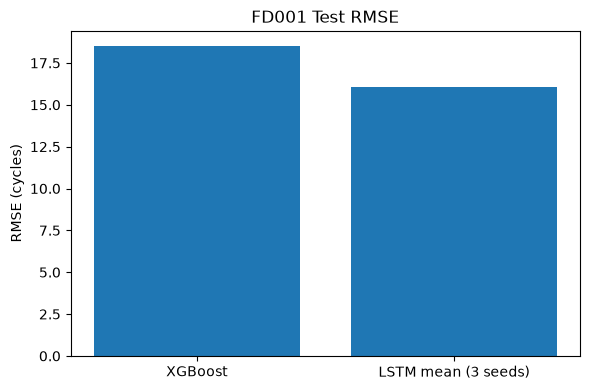

In [12]:
plt.figure(figsize=(6, 4))

plot_data = main_comparison[["Model", "RMSE"]]

plt.bar(
    plot_data["Model"],
    plot_data["RMSE"]
)

plt.ylabel("RMSE (cycles)")
plt.title("FD001 Test RMSE")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "rmse_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## 13. MAE comparison plot


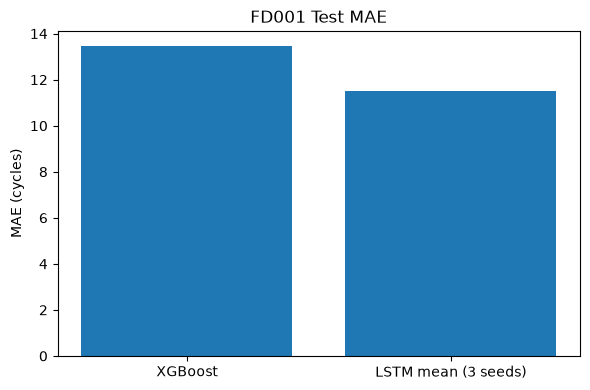

In [13]:
plt.figure(figsize=(6, 4))

plot_data = main_comparison[["Model", "MAE"]]

plt.bar(
    plot_data["Model"],
    plot_data["MAE"]
)

plt.ylabel("MAE (cycles)")
plt.title("FD001 Test MAE")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "mae_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## 14. Error by RUL range plot


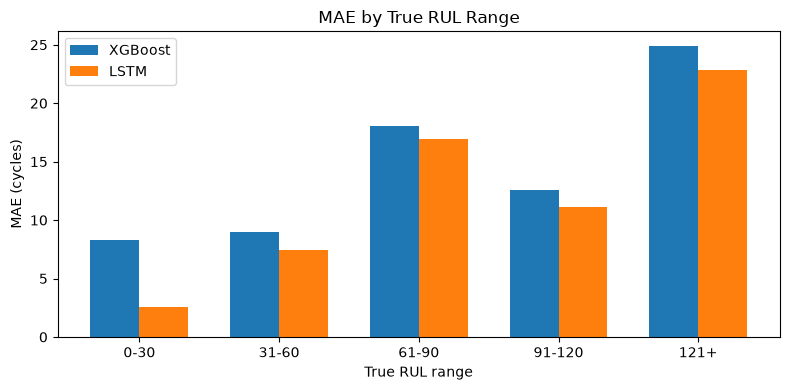

In [14]:
positions = np.arange(len(band_comparison))
width = 0.35

plt.figure(figsize=(8, 4))

plt.bar(
    positions - width / 2,
    band_comparison["XGBoost_MAE"],
    width,
    label="XGBoost"
)

plt.bar(
    positions + width / 2,
    band_comparison["LSTM_MAE"],
    width,
    label="LSTM"
)

plt.xticks(
    positions,
    band_comparison["RUL_band"]
)

plt.xlabel("True RUL range")
plt.ylabel("MAE (cycles)")
plt.title("MAE by True RUL Range")
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "mae_by_rul_band.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## 15. Actual and predicted RUL

This plot shows both models against the real RUL values.


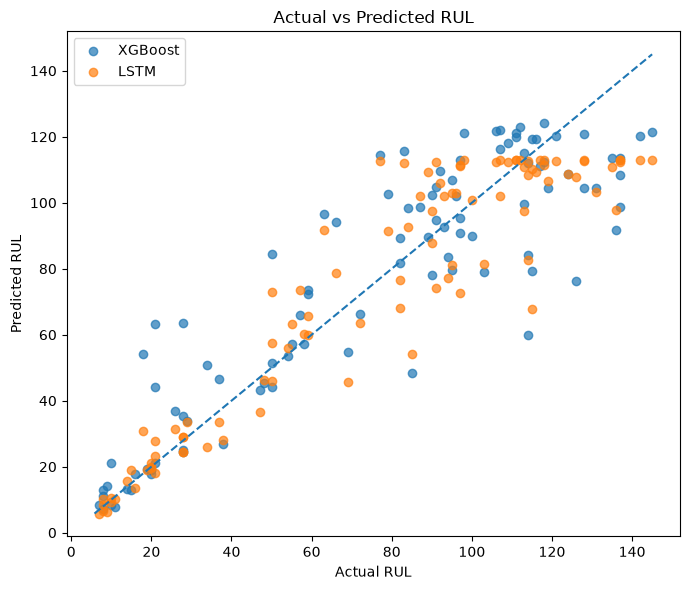

In [15]:
plt.figure(figsize=(7, 6))

plt.scatter(
    engine_comparison["actual_RUL"],
    engine_comparison["xgboost_prediction"],
    label="XGBoost",
    alpha=0.7
)

plt.scatter(
    engine_comparison["actual_RUL"],
    engine_comparison["lstm_prediction"],
    label="LSTM",
    alpha=0.7
)

minimum = min(
    engine_comparison["actual_RUL"].min(),
    engine_comparison["xgboost_prediction"].min(),
    engine_comparison["lstm_prediction"].min()
)

maximum = max(
    engine_comparison["actual_RUL"].max(),
    engine_comparison["xgboost_prediction"].max(),
    engine_comparison["lstm_prediction"].max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("Actual vs Predicted RUL")
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "actual_vs_predicted_both_models.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## 16. Difference in absolute error by engine

Values above zero mean the LSTM had the smaller absolute error.

Values below zero mean XGBoost had the smaller absolute error.


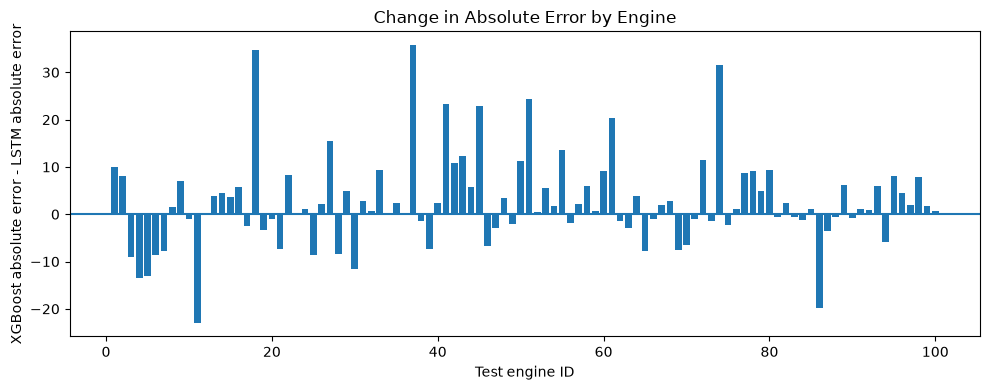

In [16]:
plt.figure(figsize=(10, 4))

plt.bar(
    engine_comparison["unit"],
    engine_comparison["absolute_error_change"]
)

plt.axhline(0)
plt.xlabel("Test engine ID")
plt.ylabel("XGBoost absolute error - LSTM absolute error")
plt.title("Change in Absolute Error by Engine")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "absolute_error_change_by_engine.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## 17. Save the final comparison files


In [17]:
main_comparison.to_csv(
    OUTPUT_DIR / "model_metric_comparison.csv",
    index=False
)

engine_comparison.to_csv(
    OUTPUT_DIR / "engine_level_comparison.csv",
    index=False
)

win_table.to_csv(
    OUTPUT_DIR / "model_wins_by_engine.csv",
    index=False
)

band_comparison.to_csv(
    OUTPUT_DIR / "rul_band_comparison.csv",
    index=False
)

xgb_worst.to_csv(
    OUTPUT_DIR / "xgboost_worst_engines.csv",
    index=False
)

lstm_worst.to_csv(
    OUTPUT_DIR / "lstm_worst_engines.csv",
    index=False
)

summary = {
    "xgboost_test_rmse": float(xgb_metrics["test_rmse"]),
    "xgboost_test_mae": float(xgb_metrics["test_mae"]),
    "xgboost_test_r2": float(xgb_metrics["test_r2"]),
    "xgboost_nasa_score": float(xgb_metrics["test_nasa_score"]),
    "lstm_mean_test_rmse": float(lstm_mean_rmse),
    "lstm_std_test_rmse": float(lstm_std_rmse),
    "lstm_mean_test_mae": float(lstm_mean_mae),
    "lstm_std_test_mae": float(lstm_std_mae),
    "lstm_mean_test_r2": float(lstm_mean_r2),
    "lstm_mean_nasa_score": float(lstm_mean_nasa),
    "lstm_ensemble_rmse": float(lstm_ensemble["RMSE"]),
    "lstm_ensemble_mae": float(lstm_ensemble["MAE"]),
    "lstm_ensemble_r2": float(lstm_ensemble["R2"]),
    "lstm_ensemble_nasa_score": float(lstm_ensemble["NASA_score"]),
    "rmse_improvement_percent": float(rmse_improvement),
    "mae_improvement_percent": float(mae_improvement),
    "lstm_engine_wins": int(lstm_wins),
    "xgboost_engine_wins": int(xgb_wins),
    "ties": int(ties),
    "xgboost_training_seconds": float(xgb_training_time),
    "lstm_mean_training_seconds": float(lstm_mean_training_time)
}

with open(
    OUTPUT_DIR / "comparison_summary.json",
    "w"
) as f:
    json.dump(summary, f, indent=2)

print("Saved comparison outputs to:", OUTPUT_DIR.resolve())

Saved comparison outputs to: C:\Users\ak587\Downloads\New folder\comparison_outputs


## 18. Main results from the completed model runs

The final XGBoost test result was:

- RMSE: **18.4838 cycles**
- MAE: **13.4419 cycles**
- R²: **0.8022**
- NASA score: **630.95**

The LSTM was trained with three random seeds.

The mean LSTM result was:

- RMSE: **16.0610 ± 1.1059 cycles**
- MAE: **11.5121 ± 0.7419 cycles**
- R²: **0.8501**
- NASA score: **403.38**

Compared with XGBoost, the mean LSTM result reduced:

- RMSE by **13.11%**
- MAE by **14.36%**

The averaged prediction from all three LSTM runs gave:

- RMSE: **14.9067 cycles**
- MAE: **10.8442 cycles**
- R²: **0.8713**
- NASA score: **308.77**

The averaged prediction is useful as an extra result, but the mean and standard deviation across the three separate LSTM runs are the main results because they show how stable the model was.


## 19. Error by RUL range

The final MAE values were:

| True RUL | XGBoost MAE | LSTM MAE |
|---|---:|---:|
| 0-30 | 8.30 | 2.53 |
| 31-60 | 9.00 | 7.44 |
| 61-90 | 18.06 | 16.96 |
| 91-120 | 12.61 | 11.10 |
| 121+ | 24.90 | 22.80 |

The LSTM had a lower MAE in every RUL group.

The biggest difference was close to failure, in the 0-30 cycle group.

Both models had their largest error for engines with more than 121 cycles left. Both models also tended to predict too little RUL for this group.


## 20. Final project interpretation

The LSTM gave better test results than XGBoost on FD001.

This supports the idea that using the order of sensor readings over time can help with RUL prediction.

The improvement was useful but not extremely large. XGBoost still gave a strong result and trained much faster.

In the recorded runs, XGBoost took about **0.79 seconds** to train. The LSTM took about **40.34 seconds per seed** on average.

The main difference between the models was seen close to failure. For engines with 0-30 cycles left, the LSTM MAE was about 2.53 cycles compared with 8.30 cycles for XGBoost.

Both models found high-RUL engines more difficult. This means the models were better at recognising later degradation than estimating the remaining life of engines that were still far from failure.

### Answer to the research question

Under the same engine-level evaluation setup, the LSTM performed better than XGBoost for RUL prediction on FD001. The lower RMSE and MAE suggest that using 30-cycle sensor sequences gave the LSTM useful time information that was not fully captured by the rolling features used with XGBoost.

At the same time, XGBoost was much faster to train and remained competitive. This shows a trade-off between prediction accuracy and model cost.


## 21. Limitations

There are a few limits to this experiment.

- Only the FD001 dataset was used.
- FD001 has one operating condition and one fault type.
- One XGBoost setup and one LSTM setup were compared.
- The LSTM was tested with three random seeds.
- The C-MAPSS data is simulated, so real industrial data may behave differently.
- Training time depends on the computer being used.

Because of this, the results show what happened in this experiment. They do not mean that LSTM will always perform better than XGBoost for every predictive maintenance problem.


## 22. Project log

### What I did

I compared the final XGBoost and LSTM models using the same 100 FD001 test engines.

I checked RMSE, MAE, R², NASA score, training time, errors for each engine and errors at different RUL ranges.

### Main results

XGBoost achieved:

- RMSE: 18.4838
- MAE: 13.4419
- R²: 0.8022
- NASA score: 630.95

The LSTM mean across three seeds achieved:

- RMSE: 16.0610
- MAE: 11.5121
- R²: 0.8501
- NASA score: 403.38

The LSTM improved RMSE by 13.11% and MAE by 14.36%.

The averaged LSTM prediction achieved an RMSE of 14.9067 and an MAE of 10.8442.

### Engine-level comparison

The LSTM had the lower absolute error for 61 of the 100 test engines.

XGBoost had the lower absolute error for 39 engines.

There were no ties.

### RUL ranges

The LSTM had a lower MAE than XGBoost in all five RUL groups.

The biggest improvement was for engines with 0-30 cycles remaining.

Both models had their highest errors when the true RUL was above 121 cycles.

### Training time

XGBoost took about 0.784 seconds to train.

The LSTM took about 40.337 seconds per seed on average and about 121.01 seconds for all three runs.

### Final finding

The LSTM gave better prediction accuracy, while XGBoost was much faster to train.

The results suggest that using time-ordered sensor sequences helped RUL prediction on FD001.
